In [72]:
import math
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform

data_path = './data_notebook/data/'

# Machine Learning
The discipline of creating machines able to learn.

- Learn what? A model
- To solve what? A task
- Learn how? By using a learning algorithm
- Learning by? Searching

In [73]:
df = pd.read_csv(f'{data_path}adult.csv')

In [74]:
df

,age,capital_gain,capital_loss,education,final_weight,hours_worked_per_week,marital_status,native_country,occupation,race,relationship,is_male,workclass,over_threshold
0,43,0.0,0.0,10,34278,35,Married-civ-spouse,United-States,Sales,White,Husband,True,Private,0
1,23,0.0,0.0,3,244698,35,Never-married,Mexico,Farming-fishing,White,Other-relative,True,Private,0
2,39,0.0,0.0,10,118286,40,Married-civ-spouse,United-States,Sales,Black,Husband,True,Private,0
3,35,0.0,0.0,9,126675,46,Divorced,?,Craft-repair,White,Not-in-family,True,Private,0
4,66,0.0,0.0,13,28367,99,Married-civ-spouse,United-States,Priv-house-serv,White,Other-relative,True,Private,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36626,40,0.0,0.0,10,279679,45,Divorced,United-States,Exec-managerial,White,Not-in-family,True,Private,0
36627,40,0.0,0.0,10,323790,40,Married-civ-spouse,United-States,Other-service,White,Husband,True,Private,0
36628,38,0.0,0.0,10,78247,40,Married-civ-spouse,United-States,Exec-managerial,White,Husband,True,Private,0
36629,53,0.0,0.0,14,92565,40,Married-civ-spouse,United-States,Prof-specialty,Asian-Pac-Islander,Husband,True,Private,1


### Encoding the categorical variables
We can discretize the categorical variables and then use them for the classification task. NB: for some classifiers it may not be a good practice (example: classifiers which use distance metrics for the classifications, such as KNN).

Encoding also highly depends on the model we wish to train, so adapt it accordingly!

In [27]:
from sklearn.preprocessing import LabelEncoder
cat_col = ['relationship', 'race', 'is_male', 'occupation', 'marital_status', 
             'workclass', 'native_country', 'education']

le = LabelEncoder()
# Apply to each column
for col in cat_col + ['over_threshold']:
    df[col] = le.fit_transform(df[col])

In [28]:
df

,age,capital_gain,capital_loss,education,final_weight,hours_worked_per_week,marital_status,native_country,occupation,race,relationship,is_male,workclass,over_threshold
0,43,0.0,0.0,9,34278,35,2,39,12,4,0,1,4,0
1,23,0.0,0.0,2,244698,35,4,26,5,4,2,1,4,0
2,39,0.0,0.0,9,118286,40,2,39,12,2,0,1,4,0
3,35,0.0,0.0,8,126675,46,0,0,3,4,1,1,4,0
4,66,0.0,0.0,12,28367,99,2,39,9,4,2,1,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36626,40,0.0,0.0,9,279679,45,0,39,4,4,1,1,4,0
36627,40,0.0,0.0,9,323790,40,2,39,8,4,0,1,4,0
36628,38,0.0,0.0,9,78247,40,2,39,4,4,0,1,4,0
36629,53,0.0,0.0,13,92565,40,2,39,10,1,0,1,4,1


In [29]:
df_encoded = pd.get_dummies(df, columns=cat_col, prefix_sep='%')

In [30]:
df_encoded.head()

,age,capital_gain,capital_loss,final_weight,hours_worked_per_week,over_threshold,relationship%0,relationship%1,relationship%2,relationship%3,...,education%6,education%7,education%8,education%9,education%10,education%11,education%12,education%13,education%14,education%15
0,43,0.0,0.0,34278,35,0,True,False,False,False,...,False,False,False,True,False,False,False,False,False,False
1,23,0.0,0.0,244698,35,0,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
2,39,0.0,0.0,118286,40,0,True,False,False,False,...,False,False,False,True,False,False,False,False,False,False
3,35,0.0,0.0,126675,46,0,False,True,False,False,...,False,False,True,False,False,False,False,False,False,False
4,66,0.0,0.0,28367,99,0,False,False,True,False,...,False,False,False,False,False,False,True,False,False,False


# Supervised Learning

**Supervised learning** is a type of machine learning where the model is trained using a **labeled dataset**.  

- Each training example consists of:
  - **Input features $(X)$** – the data used to make predictions.
  - **Target label/output $(y)$** – the value we want the model to predict.

The goal is to learn a function $ f(X) $ that maps inputs to outputs as accurately as possible.

---
**Types of Supervised Learning**

1. **Regression**  
   - Target \( y \) is **continuous** (numerical).  
   - Goal: predict a numeric value.  
   - Example: predicting house prices, temperature, or sales.

2. **Classification**  
   - Target \( y \) is **categorical** (discrete labels).  
   - Goal: assign the correct class to each input.  
   - Example: spam vs. not spam, type of fruit, disease diagnosis.


**How it works:**
1. **Collect labeled data** – features and correct labels.  
2. **Train a model** – learn patterns from data.  
3. **Validate the model** – evaluate performance on unseen data.  
4. **Predict** – make predictions on new inputs.

---

# Decision Trees

A **Decision Tree** is a supervised learning model used for both **classification** and **regression**.  
It is structured like a flowchart: internal nodes are feature-based decisions, branches are outcomes, and leaves are predictions.

1. Start with all data at the root.  
2. Choose the best feature & split that improves purity (classification) or reduces error (regression).  
3. Recursively split child nodes until a stopping criterion is met (max depth, min samples, pure leaf, etc.).

---

## Splitting criteria

- **Gini Impurity**
  $$
  \text{Gini}(D) = 1 - \sum_{i=1}^{C} p_i^2
  $$
  where $p_i$ is the fraction of samples of class \(i\) in node \(D\).  
  Gini = 0 means the node is pure (all samples same class).

- **Entropy (Information Gain)**
  $$
  \text{Entropy}(D) = -\sum_{i=1}^{C} p_i \log_2 p_i
  $$
  Information gain from splitting on attribute \(A\):
  $$
  IG(D, A) = \text{Entropy}(D) - \sum_{v \in \text{Values}(A)} \frac{|D_v|}{|D|}\,\text{Entropy}(D_v)
  $$
  Measures the uncertainty (disorder) of the node. Information Gain (IG) tells how much entropy is reduced n after a split on attribute $A$.

---

## Advantages
- Easy to interpret and visualize (white-box model).  
- Works with numerical and categorical features.  
- Minimal preprocessing (no scaling required).  

## Limitations
- Prone to overfitting unless pruned or constrained (max depth, min samples).  
- High variance: small changes in data can produce very different trees.  
- Typically less accurate than ensemble methods (Random Forest, Gradient Boosting).
---

## Gini vs Entropy

| Criterion | Interpretation | Tends to |
|---|---|---|
| Gini | $$1 - \sum p_i^2$$ | favor splits that isolate the largest class (slightly faster) |
| Entropy | $$-\sum p_i \log_2 p_i$$ | more theoretically grounded (information gain), may be slightly more sensitive to changes in class distribution |


In [31]:
#to classify, we first need to split the dataset into train and test dataset.
#we can do so using train_test_split, in this case we select a stratified split
from sklearn.model_selection import train_test_split
label = df.pop('over_threshold')
train_set, test_set, train_label, test_label = train_test_split(df, label, stratify =label, test_size=0.30)

In [32]:
#define a decision tree and fit it
from sklearn import tree
dt = tree.DecisionTreeClassifier(criterion='gini', splitter='best', 
                                  max_depth=10, 
                                  min_samples_split=3, min_samples_leaf=4)
dt = dt.fit(train_set, train_label)

In [33]:
# To visualize the Decision Tree, you must intsall GraphViz
# MacOs: brew install graphviz
# Linux: sudo apt-get install graphviz
# Windows: Install from here https://graphviz.org/download/ 
# and add the following enviroment variable (the path can change)
# import os
# os.environ["PATH"] += os.pathsep + 'C:\Program Files (x86)\Graphviz2.38/bin/'



In [34]:
#visualize the actual decision tree obtained 
import pydotplus 
from IPython.display import Image  
dot_data = tree.export_graphviz(dt, out_file=None, 
                         feature_names=list(train_set.columns),  
                         class_names=['<=50', '>50'],  
                         filled=True, rounded=True)  
graph = pydotplus.graph_from_dot_data(dot_data)  
Image(graph.create_png())

In [35]:
#predict using the decision tree
#the predict function returns the actual predicted labels: we need them for the evaluation phase
train_pred_dt = dt.predict(train_set)
test_pred_dt = dt.predict(test_set)

### Evaluation of the decision tree: compute accuracy, precision, recall, confusion matrix

<img src="data_notebook/images/metrics.png" alt="Metrics" width="1000">

In [36]:
#evaulate the accuracy on the train set and the test set
#metrics also contains precision, recall, f1 and the support
from sklearn import metrics
print('Accuracy train set ', metrics.accuracy_score(train_label, train_pred_dt))
print('Accuracy test set ', metrics.accuracy_score(test_label, test_pred_dt))
print('Precision train set ', metrics.precision_score(train_label, train_pred_dt, average='weighted'))
print('Recall train set ', metrics.recall_score(train_label, train_pred_dt, average='weighted'))
print('F1 score train set ', metrics.f1_score(train_label, train_pred_dt, average='weighted'))
print('Support train set ', metrics.precision_recall_fscore_support(train_label, train_pred_dt))

Accuracy train set  0.8672438672438673
Accuracy test set  0.8481346678798908
Precision train set  0.8637009209466847
Recall train set  0.8672438672438673
F1 score train set  0.8648884175232404
Support train set  (array([0.90066687, 0.7461691 ]), array([0.92781708, 0.67465363]), array([0.9140404 , 0.70861154]), array([19506,  6135]))


In [37]:
#metrics computed on the test set
from sklearn.metrics import classification_report
def report_scores(test_label, test_pred):
    print(classification_report(test_label, 
                            test_pred, 
                            target_names=['<=50', '>50']))

In [38]:
report_scores(test_label, test_pred_dt)

              precision    recall  f1-score   support

        <=50       0.89      0.92      0.90      8360
         >50       0.70      0.63      0.67      2630

    accuracy                           0.85     10990
   macro avg       0.80      0.77      0.78     10990
weighted avg       0.84      0.85      0.85     10990



In [39]:
#compute confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(test_label, test_pred_dt)
cm

array([[7659,  701],
       [ 968, 1662]])

In [40]:
cm.shape

(2, 2)

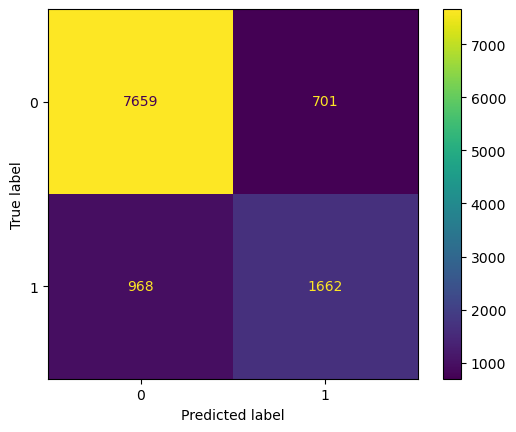

In [41]:
#it is possible to plot the confusion matrix 
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=dt.classes_)
disp.plot()
plt.show()

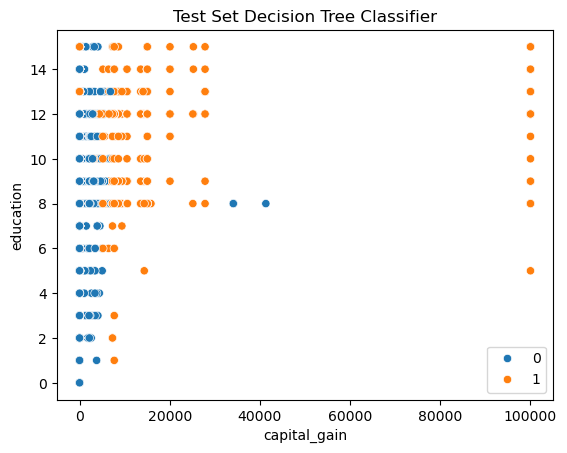

In [42]:
sns.scatterplot(data=test_set, x="capital_gain", y="education", hue=test_label.values)
plt.title('Test Set Decision Tree Classifier')
plt.show()

# Cross validation

<img src="data_notebook/images/grid_search_workflow.png" alt="Cross-validation diagram" width="400">

<img src="data_notebook/images/grid_search_cross_validation.png" alt="Cross-validation diagram" width="500">

**Cross-validation** is a technique used to **assess the performance and generalization ability** of a machine learning model.  
Instead of evaluating a model on a single train/test split, cross-validation splits the data multiple times to obtain a more reliable estimate of performance.

---

### (K-Fold Cross-Validation)

1. **Split** the dataset into $K$ equal-sized folds.  
2. **Iterate** over each fold:
   - Use $K-1$ folds as **training data**.  
   - Use the remaining 1 fold as **validation data**.  
3. **Train and evaluate** the model on each split.  
4. **Average the performance** across all folds to get the final score.

- Each data point is used **once as validation** and **K-1 times as training**.  

---

### Variants of Cross-Validation

- **K-Fold CV** – dataset is split into K folds (most common).  
- **Stratified K-Fold** – ensures each fold has the same **class distribution** (important for classification). 
- **Leave-One-Out CV (LOOCV)** – each sample is used once as validation (very expensive for large datasets).  
- **Repeated CV** – repeat K-Fold multiple times to reduce variability.  

---

Cross-validation allows you to train and test a model multiple times on different subsets of the data, giving a more **reliable estimate of performance** and helping to **avoid overfitting**.


## Underfitting and Overfitting 

<img src="data_notebook/images/overfitting_underfitting.webp" alt="Underfitting and Overfitting" width="500">

In [43]:
#the score array for test/train scores on each cv split
#the time for fitting/scoring the estimator on the train set for each cv split
from sklearn.model_selection import cross_validate
import statistics 
scores = cross_validate(dt, train_set, train_label, cv=3, return_train_score= True)
print('Fit time ', statistics.mean(scores['fit_time']))
print('Score time ', statistics.mean(scores['score_time']))
print('Test score ', statistics.mean(scores['test_score']))
print('Train score ', statistics.mean(scores['train_score']))

Fit time  0.03259650866190592
Score time  0.001626412073771159
Test score  0.8521118521118521
Train score  0.868940368940369


# Cross validation + hyperparameters search

Each learning algorithm can be characterized by a set of hyperparameters, e.g., the architecture of a neural network, that must be set in order to learn a model.
Searching through this hyperparameter space requires a **search policy**.

In [44]:
#to find the best set of parameter setting, we can run a grid search
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
from scipy.stats import randint as sp_randint
from sklearn.metrics import make_scorer
from sklearn.metrics import accuracy_score

#define the parameters' values you want to try
param_dist = {"max_depth": [2,3,5,6,7,10,12,None],
              "max_features": sp_randint(1, len(train_set.iloc[0]) + 1),
              "min_samples_split": sp_randint(10, 51),
              "min_samples_leaf": sp_randint(10, 51),
              "criterion": ["entropy", "gini"],
              "class_weight":['balanced', None, {0: 0.3, 1: 0.7}]}
#define the number of iters
n_iter_search = 50
#define the model
clf = tree.DecisionTreeClassifier()
#define the grid search
grid_search = RandomizedSearchCV(clf, param_distributions=param_dist, 
                            n_iter=n_iter_search, 
                            n_jobs=10,
                            cv=5,                # 5-fold cross-validation
                            scoring=make_scorer(accuracy_score))
#run the grid search
grid_search.fit(train_set, train_label)

,estimator,DecisionTreeClassifier()
,param_distributions,"{'class_weight': ['balanced', None, ...], 'criterion': ['entropy', 'gini'], 'max_depth': [2, 3, ...], 'max_features': <scipy.stats....t 0x16f938cb0>, ...}"
,n_iter,50
,scoring,make_scorer(a...hod='predict')
,n_jobs,10
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [45]:
print('Best setting parameters ', grid_search.cv_results_['params'][0])
print('Mean and std of this setting ', grid_search.cv_results_['mean_test_score'][0], 
      grid_search.cv_results_['std_test_score'][0])

Best setting parameters  {'class_weight': {0: 0.3, 1: 0.7}, 'criterion': 'entropy', 'max_depth': 5, 'max_features': 13, 'min_samples_leaf': 36, 'min_samples_split': 39}
Mean and std of this setting  0.7704454405510983 0.011658120772434838


# Naive Bayes Classifier

The **Naive Bayes classifier** is a family of probabilistic models based on **Bayes’ theorem**, with the **naive assumption** that all features are independent given the class label.  

It is simple, efficient, and works surprisingly well in many applications such as text classification, spam filtering, and sentiment analysis.

---

## Bayes’ Theorem

Bayes’ theorem expresses the conditional probability of class $C_k$ given features $X = (x_1, x_2, \dots, x_n)$:

$$
P(C_k \mid X) = \frac{P(X \mid C_k) \, P(C_k)}{P(X)}
$$

- $P(C_k \mid X)$: Posterior probability (probability of class given data)  
- $P(X \mid C_k)$: Likelihood (probability of data given the class)  
- $P(C_k)$: Prior probability of the class  
- $P(X)$: Evidence (probability of the data, same for all classes)  

---

## Naive Independence Assumption

Naive Bayes assumes that features are **conditionally independent** given the class:

$$
P(X \mid C_k) = \prod_{i=1}^{n} P(x_i \mid C_k)
$$

Thus, the posterior becomes:

$$
P(C_k \mid X) \propto P(C_k) \prod_{i=1}^{n} P(x_i \mid C_k)
$$

---

## Types of Naive Bayes

Depending on how the likelihood $P(x_i \mid C_k)$ is modeled, there are different variants:

1. **Gaussian Naive Bayes**  
   - Assumes continuous features follow a normal distribution.  
   - Common in datasets with numerical variables.  

   $$
   P(x_i \mid C_k) = \frac{1}{\sqrt{2 \pi \sigma^2_{C_k}}} \exp\left(- \frac{(x_i - \mu_{C_k})^2}{2\sigma^2_{C_k}}\right)
   $$

2. **Multinomial Naive Bayes**  
   - Works well for discrete counts, e.g. word counts in text classification.  

3. **Bernoulli Naive Bayes**  
   - Works with binary features (presence/absence of a word).  

---

## Advantages
- Fast and efficient for large datasets.  
- Requires relatively few training data points.  
- Works well for high-dimensional data (e.g., text).  

## Limitations
- Assumption of feature independence is rarely true in real data.  
- If a categorical feature value never appears in training for a class, it leads to zero probability (solved via **Laplace smoothing**).  


In [46]:
#import, define and fit the model
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(train_set, train_label)

#predict on the test set
test_pred_gnb = gnb.predict(test_set)

In [47]:
#compute the performance of the model
report_scores(test_label,test_pred_gnb)

              precision    recall  f1-score   support

        <=50       0.81      0.95      0.88      8360
         >50       0.65      0.31      0.42      2630

    accuracy                           0.80     10990
   macro avg       0.73      0.63      0.65     10990
weighted avg       0.78      0.80      0.77     10990



In [48]:
test_set['capital_gain']

29447       0.0
21097       0.0
27318       0.0
30480       0.0
831         0.0
          ...  
20939       0.0
32995       0.0
3715     9386.0
24269       0.0
24184       0.0
Name: capital_gain, Length: 10990, dtype: float64

In [49]:
test_set

,age,capital_gain,capital_loss,education,final_weight,hours_worked_per_week,marital_status,native_country,occupation,race,relationship,is_male,workclass
29447,49,0.0,0.0,9,186256,40,2,39,1,4,0,1,4
21097,58,0.0,0.0,8,75867,40,2,39,13,4,0,1,1
27318,61,0.0,0.0,2,242552,37,2,16,7,4,5,0,4
30480,57,0.0,0.0,14,315460,36,2,39,10,4,0,1,6
831,51,0.0,0.0,4,41414,40,4,39,8,2,1,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
20939,50,0.0,0.0,12,112873,40,2,39,12,4,0,1,4
32995,41,0.0,0.0,8,32627,40,0,39,8,4,1,1,4
3715,70,9386.0,0.0,13,37203,30,2,39,10,4,0,1,6
24269,44,0.0,0.0,12,188436,45,2,39,1,4,0,1,4


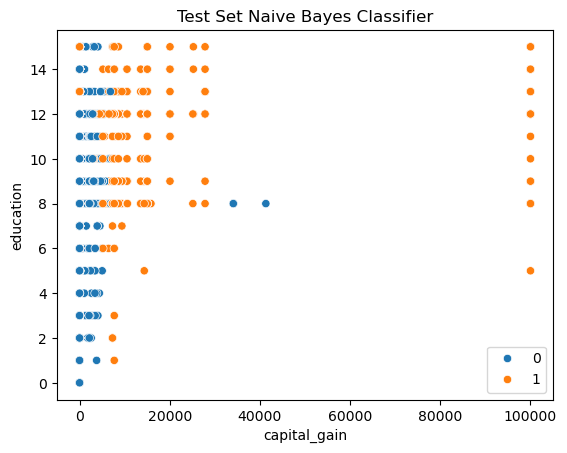

In [50]:
sns.scatterplot(data=test_set, x="capital_gain", y="education", hue=test_label.values)
plt.title('Test Set Naive Bayes Classifier')
plt.show()

# k-Nearest Neighbors (k-NN)

The **k-Nearest Neighbors (k-NN)** algorithm is a simple, non-parametric, and instance-based learning method used for **classification** and **regression**.  
It makes predictions based on the similarity between the input sample and its closest neighbors in the training set.

---

## Key Idea

Given a query point $x$, the algorithm:

1. Computes the distance between $x$ and all training samples.  
2. Selects the $k$ closest samples (neighbors).  
3. For **classification**: assigns the class most common among neighbors (majority vote).  
   $$
   \hat{y} = \arg\max_{c \in \mathcal{C}} \sum_{i=1}^{k} \mathbf{1}(y_i = c)
   $$
   where $\mathbf{1}(\cdot)$ is the indicator function.  

   For **regression**: takes the average of the neighbors’ values.  
   $$
   \hat{y} = \frac{1}{k} \sum_{i=1}^{k} y_i
   $$

---

## Choosing $k$

- **Small $k$** (e.g., $k=1$): more sensitive to noise (overfitting).  
- **Large $k$**: smoother decision boundary but may underfit.  

---

## Advantages
- Simple and easy to implement.  
- No assumptions about data distribution.  
- Works well for low-dimensional data.  

## Limitations
- Computationally expensive for large datasets (must store all training data).  
- Sensitive to irrelevant features and the choice of distance metric.  
- Struggles in high-dimensional spaces (**curse of dimensionality**). 

<img src="images/knn.webp" alt="Knn" width="500">

In [51]:
#drop the categorical features
num_col = ['age', 'capital_gain', 'capital_loss', 'education', 'final_weight', 'hours_worked_per_week']
train_set_num = train_set[num_col] 
test_set_num = test_set[num_col] 

In [52]:
from sklearn.neighbors import KNeighborsClassifier
#['auto', 'ball_tree', 'kd_tree', 'brute']
knn = KNeighborsClassifier(n_neighbors=2, algorithm='ball_tree', metric='minkowski')
knn.fit(train_set_num, train_label)

,n_neighbors,2
,weights,'uniform'
,algorithm,'ball_tree'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [53]:
#prediction on the test test
test_pred_knn = knn.predict(test_set_num)

In [54]:
#compute the performance of the model
report_scores(test_label,test_pred_knn)

              precision    recall  f1-score   support

        <=50       0.80      0.95      0.87      8360
         >50       0.62      0.26      0.36      2630

    accuracy                           0.78     10990
   macro avg       0.71      0.60      0.62     10990
weighted avg       0.76      0.78      0.75     10990



# Ensemble Classifiers

## Boosting Classifier

Boosting is an **ensemble learning technique** that combines multiple **weak learners** (usually decision trees with few splits, called *stumps*) into a **strong classifier**.  
The main idea is to train models **sequentially**, where each new model focuses on the **errors (misclassified samples)** made by the previous ones (unlike bagging, weights may change at the end of each boosting round).

---

### How Boosting Works

1. **Initialize** all training samples with equal weights.  
2. Train a weak learner (e.g., decision stump).  
3. Increase the weights of misclassified samples so that the next learner focuses more on them.  
4. Train the next learner with updated weights.  
5. Repeat the process for $M$ iterations.  
6. Combine all weak learners into a strong classifier (usually by weighted voting or summation).   

---

### Advantages
- Often achieves **higher accuracy** than bagging methods (like Random Forest).  
- Focuses on **hard-to-classify samples**.  
- Works well with weak learners like decision stumps.  

---

### Limitations
- Sensitive to **outliers** (since boosting keeps focusing on misclassified points).  
- Can **overfit** if too many iterations are used.  
- Slower than bagging methods since models are trained **sequentially**.  

---

### AdaBoost (Adaptive Boosting)

**AdaBoost** is one of the first successful boosting algorithms.  
It combines multiple **weak learners** (usually decision stumps, i.e., shallow decision trees) to form a **strong classifier**.

---

### How AdaBoost Works

1. **Initialization**  
   - Start by assigning **equal weights** to all training samples.

2. **Iterative Training**  
   For each iteration $t = 1, \dots, T$:
   - Train a **weak learner** $h_t(x)$ on the dataset with the current weights.
   - Compute the **error rate** $\epsilon_t$:
     $$
     \epsilon_t = \frac{\sum_{i=1}^n w_i \cdot I(y_i \neq h_t(x_i))}{\sum_{i=1}^n w_i}
     $$
   - Compute the **learner weight** $\alpha_t$:
     $$
     \alpha_t = \frac{1}{2} \ln \left( \frac{1 - \epsilon_t}{\epsilon_t} \right)
     $$
     → weak learners with lower error get higher weight.

   - Update sample weights:
     $$
     w_i \leftarrow w_i \cdot e^{\alpha_t \cdot I(y_i \neq h_t(x_i))}
     $$
     → Misclassified points get **higher weight**, so the next learner focuses on them.

3. **Final Prediction**  
   The final model is a **weighted majority vote** of the weak learners:
   $$
   H(x) = \text{sign} \left( \sum_{t=1}^T \alpha_t h_t(x) \right)
   $$

---

### Key Intuition
- AdaBoost **adapts** by focusing on the harder-to-classify points.  
- Weak learners are trained sequentially, each improving on the mistakes of the previous ones.  

---

### Advantages
- Simple and easy to implement.  
- Works well with **weak classifiers** like decision stumps.  
- Often achieves high accuracy with little parameter tuning.  

---

### Limitations
- **Sensitive to noise and outliers** (since misclassified points get more weight).  
- Computationally slower than a single decision tree.  
- Requires weak learners that perform slightly better than random guessing.  

---

In [55]:
from sklearn.ensemble import AdaBoostClassifier

# If estimator=None, then the base estimator is DecisionTreeClassifier initialized with max_depth=1.
clf = AdaBoostClassifier()
clf.fit(train_set, train_label)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,None


In [56]:
test_pred_clf = clf.predict(test_set)
print(classification_report(test_label, 
                            test_pred_clf, 
                            target_names=['<=50', '>50']))

              precision    recall  f1-score   support

        <=50       0.86      0.96      0.91      8360
         >50       0.79      0.51      0.62      2630

    accuracy                           0.85     10990
   macro avg       0.83      0.73      0.76     10990
weighted avg       0.85      0.85      0.84     10990



Adaboost has many parameters, we can select the base classifier, which can be a DecisionTree, a Logistic Regression and so on, we can select the number of estimators and the learning rate.

In [57]:
base = tree.DecisionTreeClassifier(max_depth=5)
clf = AdaBoostClassifier(estimator=base, n_estimators=200, learning_rate=0.1)
clf.fit(train_set, train_label)

,estimator,DecisionTreeC...r(max_depth=5)
,n_estimators,200
,learning_rate,0.1
,algorithm,'deprecated'
,random_state,None
,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0


In [58]:
test_pred_clf = clf.predict(test_set)
print(classification_report(test_label, 
                            test_pred_clf, 
                            target_names=['<=50', '>50']))

              precision    recall  f1-score   support

        <=50       0.88      0.95      0.92      8360
         >50       0.80      0.59      0.68      2630

    accuracy                           0.87     10990
   macro avg       0.84      0.77      0.80     10990
weighted avg       0.86      0.87      0.86     10990



## XGBoost (Extreme Gradient Boosting)

**XGBoost** is a powerful and efficient implementation of the **Gradient Boosting** algorithm.  
It has become one of the most widely used machine learning methods in data science competitions (e.g., Kaggle) due to its **speed** and **performance**.

---

### 🔹 How XGBoost Works

1. **Gradient Boosting Idea**  
   - Train models sequentially.
   - Each new model tries to correct the **residual errors** of the previous models.
   - Instead of updating weights like in AdaBoost, Gradient Boosting minimizes a **loss function** (e.g., MSE, log loss) using **gradient descent**.

2. **XGBoost Enhancements**  
   XGBoost improves upon standard Gradient Boosting with:
   - **Regularization**: adds $L1$ (Lasso) and $L2$ (Ridge) penalties to prevent overfitting.
   - **Shrinkage (Learning Rate $\eta$)**: scales contributions of each tree to make learning more robust.
   - **Column Subsampling**: uses a random subset of features at each iteration (like Random Forest).
   - **Efficient Tree Pruning**: uses a depth-first approach and prunes branches that do not improve the objective.
   - **Parallelization**: much faster training compared to vanilla boosting.

---

### 🔹 Objective Function

The general objective minimized by XGBoost is:

$$
\mathcal{L}(\phi) = \sum_{i=1}^n l(y_i, \hat{y}_i) + \sum_{k=1}^K \Omega(f_k)
$$

- $l(y_i, \hat{y}_i)$ = loss function (e.g., squared error, logistic loss).  
- $\Omega(f_k)$ = regularization term for each tree $f_k$:  

$$
\Omega(f) = \gamma T + \frac{1}{2} \lambda \sum_{j=1}^T w_j^2
$$

where:
- $T$ = number of leaves in the tree.  
- $w_j$ = weight of leaf $j$.  
- $\gamma, \lambda$ = regularization parameters.  

---

### 🔹 Advantages of XGBoost
- **Very fast** (optimized with C++ and parallelization).  
- Handles **large datasets** efficiently.  
- Built-in **regularization** to prevent overfitting.  
- Supports **missing values** natively.  
- Works with different **objectives** (classification, regression, ranking).  

---

### 🔹 Limitations
- Can be **computationally expensive** for very high-dimensional sparse datasets.  
- Requires careful **hyperparameter tuning** (learning rate, max depth, n_estimators).  
- Sometimes less interpretable than simpler models.  

---

In [59]:
from xgboost import XGBClassifier


base_model = XGBClassifier()
hyperparameters = {
    "n_estimators": [25, 100, 250],
    "max_depth": [2, 3],
    "learning_rate": [1, 0.1, 0.001, 0.0001]
}
search = RandomizedSearchCV(base_model, hyperparameters)
search.fit(train_set, train_label)
clf = search.best_estimator_
clf.fit(train_set, train_label)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [60]:
test_pred_xgb = clf.predict(test_set)
print(classification_report(test_label, 
                            test_pred_xgb, 
                            target_names=['<=50', '>50']))

              precision    recall  f1-score   support

        <=50       0.89      0.95      0.92      8360
         >50       0.80      0.64      0.71      2630

    accuracy                           0.88     10990
   macro avg       0.85      0.79      0.82     10990
weighted avg       0.87      0.88      0.87     10990



## Bagging (Bootstrap Aggregating)

**Bagging** is an **ensemble learning technique** that improves the stability and accuracy of machine learning algorithms.  
It reduces **variance** and helps prevent **overfitting**, especially for high-variance models like decision trees.

---

### How Bagging Works

1. **Bootstrap Sampling**
   - Generate $B$ different training datasets by sampling **with replacement** from the original dataset.  
   - Each sample is called a **bootstrap sample**.

2. **Train Base Learners**
   - Train a separate model $h_b(x)$ on each bootstrap sample.  
   - Typically, the base learners are **decision trees** (leading to the famous *Random Forest* algorithm).

3. **Aggregate Predictions**
   - For **classification**:
     $$
     H(x) = \text{majority vote}(h_1(x), h_2(x), \dots, h_B(x))
     $$
   - For **regression**:
     $$
     H(x) = \frac{1}{B} \sum_{b=1}^B h_b(x)
     $$

---

### Key Intuition
- By averaging predictions from multiple diverse models:
  - **Variance decreases** → more stable predictions.
  - **Overfitting is reduced**.
- Each model sees a slightly different dataset, which makes them **less correlated**.

---

### Advantages
- Reduces overfitting of unstable learners like decision trees.  
- Works well for both regression and classification tasks.  
- Simple and parallelizable (models can be trained independently).

---

### Limitations
- **Does not reduce bias**: if the base model is weak (high bias), bagging won’t fix it.  
- Requires training multiple models → more computation.  
- Less interpretable compared to a single model.
---

In [62]:
from sklearn.ensemble import BaggingClassifier

# Bagging ensemble
bagging = BaggingClassifier(
    estimator=tree.DecisionTreeClassifier(),
    n_estimators=50,       # Number of trees
    max_samples=1.0,       # Each sample has the size of the training set
    bootstrap=True,       # Sample examples WITH replacement
    oob_score=True,        # Evaluate using out-of-bag examples
    n_jobs=-1,            # Train in parallel using all available cores
    random_state=42
)
bagging.fit(train_set, train_label)

,estimator,DecisionTreeClassifier()
,n_estimators,50
,max_samples,1.0
,max_features,1.0
,bootstrap,True
,bootstrap_features,False
,oob_score,True
,warm_start,False
,n_jobs,-1
,random_state,42
,verbose,0


In [64]:
#prediction on the test test
test_pred_bag = bagging.predict(test_set)

#compute the performance of the model
report_scores(test_label, test_pred_bag)

              precision    recall  f1-score   support

        <=50       0.89      0.93      0.91      8360
         >50       0.73      0.62      0.67      2630

    accuracy                           0.85     10990
   macro avg       0.81      0.77      0.79     10990
weighted avg       0.85      0.85      0.85     10990



## Random Forest

**Random Forest** is an **ensemble learning method** based on **Bagging** (Bootstrap Aggregating), where the base learners are **decision trees**.  
It introduces **extra randomness** by selecting a random subset of features at each split, making the trees **less correlated** and improving generalization.

---

### How Random Forest Works

1. **Bootstrap Sampling**
   - Like Bagging, generate multiple bootstrap datasets by sampling with replacement.  
   - Train a decision tree on each sample.

2. **Random Feature Selection**
   - At each split of a tree, instead of using all features, select a **random subset of features** to find the best split.  
   - This prevents all trees from looking similar and reduces correlation.

3. **Aggregation**
   - For **classification**:
     $$
     H(x) = \text{majority vote}(h_1(x), h_2(x), \dots, h_B(x))
     $$
   - For **regression**:
     $$
     H(x) = \frac{1}{B} \sum_{b=1}^B h_b(x)
     $$

---

### Key Intuition
- Random Forest = **Bagging + Random Feature Selection**.  
- By combining many **weak learners** (trees), it creates a **strong model**.  
- Works well for both **classification** and **regression** problems.

---

### Advantages
- High accuracy and robustness.  
- Reduces both **variance** (via bagging) and **correlation** (via feature randomness).  
- Handles large datasets and high-dimensional data well.  
- Provides **feature importance scores**.

---

### Limitations
- Less interpretable compared to a single decision tree.  
- Can be computationally expensive with many trees.  
- Predictions may be slower (since many trees need to be evaluated).

---

In [65]:
#define and fit a random forest
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=30, 
                             criterion='gini',
                             max_features=3,
                             max_depth=4, 
                             min_samples_split=2,
                             min_samples_leaf=8,
                             bootstrap=True) 
rf = rf.fit(train_set, train_label)

In [66]:
#prediction on the test test
test_pred_rf = rf.predict(test_set)

In [67]:
#compute the performance of the model
report_scores(test_label, test_pred_rf)

              precision    recall  f1-score   support

        <=50       0.86      0.96      0.91      8360
         >50       0.80      0.48      0.60      2630

    accuracy                           0.85     10990
   macro avg       0.83      0.72      0.75     10990
weighted avg       0.84      0.85      0.83     10990



### Class Weights

In [68]:
class_weights = {0: 0.35, 1:0.65}
rf = RandomForestClassifier(n_estimators=30, 
                             criterion='gini',
                             max_features=8,
                             max_depth=6, 
                             min_samples_split=32,
                             min_samples_leaf=10,
                             bootstrap=False,
                             class_weight= class_weights) 
rf = rf.fit(train_set, train_label)

In [69]:
#prediction on the test test
test_pred_rf = rf.predict(test_set)

#### In this way we obtain a better performance in terms of recall for the class 1, but we loose a bit on the recall of class 0.

In [70]:
#compute the performance of the model
print(classification_report(test_label, 
                            test_pred_rf, 
                            target_names=['<=50', '>50']))

              precision    recall  f1-score   support

        <=50       0.93      0.85      0.89      8360
         >50       0.62      0.78      0.69      2630

    accuracy                           0.83     10990
   macro avg       0.77      0.82      0.79     10990
weighted avg       0.85      0.83      0.84     10990



# Comparison

## AUC (Area Under the Curve)

**AUC** stands for **Area Under the Curve**.  
It is a metric used to evaluate the performance of a **binary classifier**, specifically with respect to the **ROC curve**.

---

### ROC Curve Recap
- The **Receiver Operating Characteristic (ROC) curve** plots:
  - **True Positive Rate (TPR)** = Sensitivity, Recall  
    $$
    TPR = \frac{TP}{TP + FN}
    $$
  - **False Positive Rate (FPR)**  
    $$
    FPR = \frac{FP}{FP + TN}
    $$

- The curve shows the trade-off between TPR and FPR at different classification thresholds.

---

### What is AUC?
- **AUC** is the **area under the ROC curve**.  
- It measures the ability of the classifier to distinguish between the two classes.

- Interpretation:
  - **AUC = 1.0** → Perfect classifier.  
  - **AUC = 0.5** → No discriminative ability (random guessing).  
  - **AUC < 0.5** → Worse than random (model is likely flipped).

---

### Why AUC is Useful
- Threshold-independent: evaluates performance across **all possible thresholds**.  
- Robust to class imbalance (unlike simple accuracy).  
- Gives an intuitive measure of **ranking ability**:  
  > AUC = probability that the classifier ranks a randomly chosen positive higher than a randomly chosen negative.

---

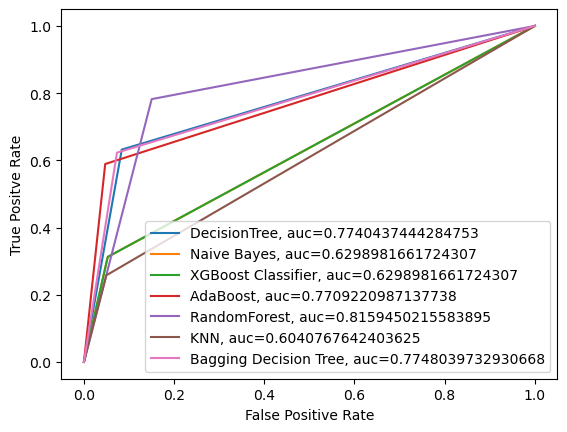

In [71]:
from sklearn import metrics
import numpy as np
import matplotlib.pyplot as plt

plt.figure(0).clf()

fpr, tpr, thresh = metrics.roc_curve(test_label, test_pred_dt)
auc = metrics.roc_auc_score(test_label, test_pred_dt)
plt.plot(fpr,tpr,label="DecisionTree, auc="+str(auc))

fpr, tpr, thresh = metrics.roc_curve(test_label, test_pred_gnb)
auc = metrics.roc_auc_score(test_label, test_pred_gnb)
plt.plot(fpr,tpr,label="Naive Bayes, auc="+str(auc))

fpr, tpr, thresh = metrics.roc_curve(test_label, test_pred_gnb)
auc = metrics.roc_auc_score(test_label, test_pred_gnb)
plt.plot(fpr,tpr,label="XGBoost Classifier, auc="+str(auc))

fpr, tpr, thresh = metrics.roc_curve(test_label, test_pred_clf)
auc = metrics.roc_auc_score(test_label, test_pred_clf)
plt.plot(fpr,tpr,label="AdaBoost, auc="+str(auc))

fpr, tpr, thresh = metrics.roc_curve(test_label, test_pred_rf)
auc = metrics.roc_auc_score(test_label, test_pred_rf)
plt.plot(fpr,tpr,label="RandomForest, auc="+str(auc))


fpr, tpr, thresh = metrics.roc_curve(test_label, test_pred_knn)
auc = metrics.roc_auc_score(test_label, test_pred_knn)
plt.plot(fpr,tpr,label="KNN, auc="+str(auc))

fpr, tpr, thresh = metrics.roc_curve(test_label, test_pred_bag)
auc = metrics.roc_auc_score(test_label, test_pred_bag)
plt.plot(fpr,tpr,label="Bagging Decision Tree, auc="+str(auc))



plt.xlabel('False Positive Rate')
plt.ylabel('True Positve Rate')

plt.legend(loc=0)

plt.show()

# Rule-based Classifiers

## RIPPER (Repeated Incremental Pruning to Produce Error Reduction)

**RIPPER** is a **rule-based classification algorithm**.  
Instead of building decision trees, it generates **IF–THEN rules** that classify data into categories.  
It is widely used in **data mining** because it balances **accuracy** and **interpretability**.

---

### How RIPPER Works

1. **Grow Phase**
   - Build a rule by **adding conditions** (attribute tests) until it **perfectly classifies** a subset of training instances.  

2. **Prune Phase**
   - Remove unnecessary conditions from the rule to **reduce overfitting**.  
   - A rule is kept if it improves performance on a validation set.

3. **Rule Set Formation**
   - Add the rule to the rule set.  
   - Remove the covered examples from the training set.  
   - Repeat the process until all (or most) examples are covered.  

4. **Optimization Phase**
   - Refine the rule set by replacing or revising rules to minimize classification error.

---

### Advantages
- Produces **interpretable rules** (easy to understand).  
- Works efficiently on large datasets.  
- Pruning helps handle **noisy data**.  

---

### Limitations
- Rules can be unstable if the dataset changes significantly.  
- Works best with categorical or discretized features.  
- May not reach the accuracy of advanced ensemble methods (e.g., Random Forest, XGBoost).  

---

#### There are several rule-based methods. One of the most popular is RIPPER. To use it, you have to install it using !pip install wittgenstein. The documentation of this method can be found in https://github.com/imoscovitz/wittgenstein

In [99]:
# prune_size: change the grow/prune proportion
# k: the number of optimization runs

#define and fit the rule-based model
#this function requires only one dataset with the labels. 
#To do so, we concatenate the train_set and the train_label
import wittgenstein as lw
ripper = lw.RIPPER(k=1, prune_size=0.50)
ripper.fit(trainset=train_set, y=train_label, pos_class=1)

#prediction on the test test
test_pred_ripper = ripper.predict(test_set)

In [100]:
#compute the performance of the model
print(classification_report(test_label, 
                            test_pred_ripper, 
                            target_names=['<=50', '>50']))

              precision    recall  f1-score   support

        <=50       0.83      0.97      0.89      8360
         >50       0.78      0.38      0.51      2630

    accuracy                           0.83     10990
   macro avg       0.81      0.67      0.70     10990
weighted avg       0.82      0.83      0.80     10990



In [101]:
#in this case the model is a set of rules
ripper.out_model()

[[marital_status=2 ^ education=10.0-12.0 ^ occupation=3.0-4.0 ^ hours_worked_per_week=48.0-55.0 ^ age=37.0-41.0 ^ capital_loss=1742.4-2178.0] V
[marital_status=2 ^ education=10.0-12.0 ^ occupation=3.0-4.0 ^ hours_worked_per_week=48.0-55.0 ^ workclass=4 ^ age=45.0-51.0] V
[marital_status=2 ^ education=10.0-12.0 ^ occupation=3.0-4.0 ^ hours_worked_per_week=48.0-55.0 ^ workclass=4 ^ race=4 ^ relationship=0 ^ age=33.0-37.0] V
[marital_status=2 ^ education=>12.0 ^ capital_gain=9999.9-19999.8] V
[marital_status=2 ^ education=10.0-12.0 ^ workclass=4 ^ occupation=3.0-4.0 ^ hours_worked_per_week=48.0-55.0 ^ age=51.0-58.0] V
[marital_status=2 ^ education=10.0-12.0 ^ occupation=3.0-4.0 ^ capital_gain=9999.9-19999.8] V
[marital_status=2 ^ education=10.0-12.0 ^ occupation=3.0-4.0 ^ capital_loss=1742.4-2178.0 ^ hours_worked_per_week=35.0-40.0] V
[marital_status=2 ^ occupation=8.0-10.0 ^ education=>12.0 ^ workclass=5] V
[marital_status=2 ^ education=10.0-12.0 ^ occupation=3.0-4.0 ^ final_weight=19634

In [103]:
#with rule based classifiers it is possible to extract the reasons for the prediction.
#only for the positive predictions
ripper.predict(test_set[:100], give_reasons=True)

([False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  True,
  False,
  False,
  False,
  False,
  False,
  True,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  True,
  True,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  True,
  True,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  False,
  True,
  True,
  False,
  False,
  True,
  True,
  False,
  False,
  False,
  False],
 [[],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
  [],
 

# Neural Networks

A **Neural Network (NN)** is a computational model inspired by the **structure and function of the human brain**.  
It is composed of layers of interconnected **neurons (nodes)** that process input data to produce an output.

---

### Structure of a Neural Network

1. **Input Layer**  
   - Receives the features of the dataset.  
   - Each neuron corresponds to one input feature.

2. **Hidden Layers**  
   - One or more layers between input and output.  
   - Each neuron computes a **weighted sum** of its inputs and applies a **non-linear activation function**:
     $$
     h_j = f\Big(\sum_{i} w_{ij} x_i + b_j \Big)
     $$
     where:
     - $x_i$ = input to neuron $j$  
     - $w_{ij}$ = weight of input $i$  
     - $b_j$ = bias term  
     - $f$ = activation function (ReLU, sigmoid, tanh, etc.)

3. **Output Layer**  
   - Produces the final prediction.  
   - For classification, often uses **softmax** (multi-class) or **sigmoid** (binary).  
   - For regression, typically a **linear activation**.

---

### Training a Neural Network

- **Forward Propagation**: Compute the output by passing inputs through the network.  
- **Loss Function**: Measure the difference between predicted and actual values (e.g., cross-entropy for classification).  
- **Backward Propagation (Backpropagation)**: Compute gradients of the loss w.r.t. weights using **chain rule**.  
- **Optimization**: Update weights using **gradient descent** or variants (Adam, RMSProp, etc.):

$$
w_{ij} \leftarrow w_{ij} - \eta \frac{\partial L}{\partial w_{ij}}
$$

where $\eta$ is the **learning rate**.

- Repeat the process over multiple **epochs** until convergence.

---

### Key Features
- Can approximate **complex, non-linear functions**.  
- Works with large amounts of data.  
- Can be used for **classification, regression, sequence modeling, and more**.

---

### Advantages
- High flexibility and expressiveness.  
- Can model complex patterns in data.  
- Suitable for **deep learning** architectures.

---

### Limitations
- Requires **large datasets** for training.  
- Computationally intensive.  
- Harder to interpret compared to simpler models.  
- Sensitive to **hyperparameters** (learning rate, architecture, activation functions).

---

In [105]:
# X_train = np.reshape(train_set.values, (train_set.shape[0], 1, train_set.shape[1]))
# y_train = np.asarray(train_label).astype('float32').reshape((-1,1))
# print(X_train.shape)
# print(y_train.shape)

(25641, 1, 13)
(25641, 1)


In [112]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# model = tf.keras.models.Sequential([
#   tf.keras.layers.Flatten(input_shape=(1, 13)),
#   tf.keras.layers.Dense(32, activation='sigmoid'),  
#   tf.keras.layers.Dense(1, activation='sigmoid')
# ])

model = Sequential()
model.add(Input(shape=(train_set.shape[1],)))   # Input layer
model.add(Dense(32, activation='sigmoid'))       # Hidden layer
model.add(Dense(1, activation='sigmoid'))     # Output layer

# Compile the model
model.compile(optimizer='adamax',
              loss='mean_squared_error',
              metrics=['accuracy'])

In [113]:
history = model.fit(train_set.values, train_label.values,
                    epochs=80,
                    batch_size=512,
                    validation_split=0.2)

Epoch 1/80
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2423 - loss: 0.3330 - val_accuracy: 0.7623 - val_loss: 0.2419
Epoch 2/80
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 598us/step - accuracy: 0.7619 - loss: 0.2264 - val_accuracy: 0.7610 - val_loss: 0.1999
Epoch 3/80
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 523us/step - accuracy: 0.7655 - loss: 0.1929 - val_accuracy: 0.7610 - val_loss: 0.1902
Epoch 4/80
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - accuracy: 0.7558 - loss: 0.1880 - val_accuracy: 0.7610 - val_loss: 0.1874
Epoch 5/80
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 506us/step - accuracy: 0.7608 - loss: 0.1835 - val_accuracy: 0.7610 - val_loss: 0.1865
Epoch 6/80
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 500us/step - accuracy: 0.7618 - loss: 0.1819 - val_accuracy: 0.7610 - val_loss: 0.1863
Epoch 7/80
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 497us/step - accuracy: 0.7599 - loss: 0.1826 - val_accuracy: 0.7610 - val_loss: 0.1861
Epoch 8/80
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 485us/step - accuracy: 0.7587 - loss: 0.1830 - val_accuracy: 0.76

In [114]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,445 (5.65 KB)

 Trainable params: 481 (1.88 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 964 (3.77 KB)

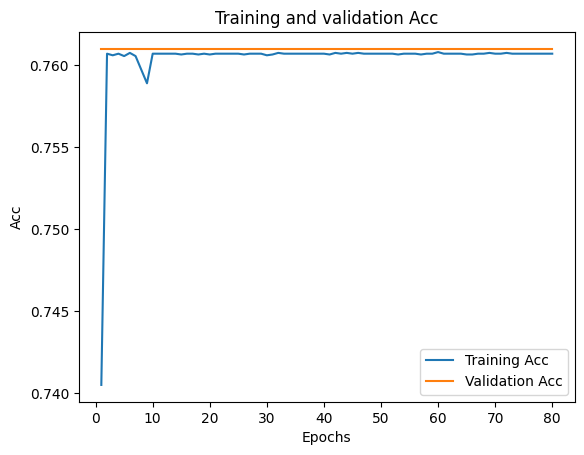

In [128]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, label='Training Acc')
plt.plot(epochs, val_acc, label='Validation Acc')
plt.title('Training and validation Acc')
plt.xlabel('Epochs')
plt.ylabel('Acc')
plt.legend()
plt.show()

In [116]:
# x_test = np.reshape(test_set.values, (test_set.shape[0], 1, test_set.shape[1]))
test_pred_nn = (model.predict(test_set.values) > 0.5).astype("int32")

344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 195us/step


In [118]:
report_scores(test_label, test_pred_nn)

              precision    recall  f1-score   support

        <=50       0.77      1.00      0.87      8360
         >50       0.98      0.02      0.05      2630

    accuracy                           0.77     10990
   macro avg       0.87      0.51      0.46     10990
weighted avg       0.82      0.77      0.67     10990



## Dropout in Neural Networks

**Dropout** is a **regularization technique** used in neural networks to reduce **overfitting** and improve **generalization**.

---

### How Dropout Works

1. **During Training**:
   - At each training step, a **random subset of neurons** in the network is temporarily **“dropped out”** (i.e., their output is set to zero).  
   - This prevents the network from relying too heavily on any single neuron or feature.

2. **Creating an Implicit Ensemble**:
   - Each mini-batch sees a slightly different network (subnetwork).  
   - The network learns **robust patterns** that do not depend on specific neurons.

3. **During Inference**:
   - Dropout is **not applied**.  
   - All neurons are used, and their outputs are often **scaled** to account for the dropout during training.  
   - This effectively averages the predictions of many subnetworks, similar to an **ensemble**.

---

### Key Benefits
- Reduces **overfitting** by forcing neurons to learn **independent and robust features**.  
- Improves **generalization** to unseen data.  
- Simple and effective, works with many types of neural networks.

In [119]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

model = Sequential([
    Input(shape=(train_set.shape[1],)),            # Input layer, 13 features
    Dense(256, activation='relu'), # First hidden layer
    Dropout(0.1),
    Dense(256, activation='relu'), # Second hidden layer
    Dropout(0.1),
    Dense(1, activation='sigmoid') # Output layer for binary classification
])

model.compile(optimizer='adamax',
              loss='mean_squared_error',
              metrics=['accuracy'])

In [120]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,633 (272.00 KB)

 Trainable params: 69,633 (272.00 KB)

 Non-trainable params: 0 (0.00 B)

In [121]:
# y_train = np.asarray(train_label).astype('float32').reshape((-1,1))
history = model.fit(train_set.values, train_label.values,
                    epochs=80,
                    batch_size=256,
                    validation_split=0.2)

Epoch 1/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6929 - loss: 0.3071 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 2/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7598 - loss: 0.2402 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 3/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7554 - loss: 0.2446 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 4/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7590 - loss: 0.2410 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 5/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7577 - loss: 0.2423 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 6/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7624 - loss: 0.2376 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 7/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7567 - loss: 0.2432 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 8/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7631 - loss: 0.2369 - val_accuracy: 0.7610 - val_loss:

Epoch 52/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7658 - loss: 0.2342 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 53/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7602 - loss: 0.2398 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 54/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7606 - loss: 0.2394 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 55/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7585 - loss: 0.2416 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 56/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7637 - loss: 0.2363 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 57/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7610 - loss: 0.2390 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 58/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7610 - loss: 0.2391 - val_accuracy: 0.7610 - val_loss: 0.2434
Epoch 59/80
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7610 - loss: 0.2390 - val_accuracy: 0.7610 - v

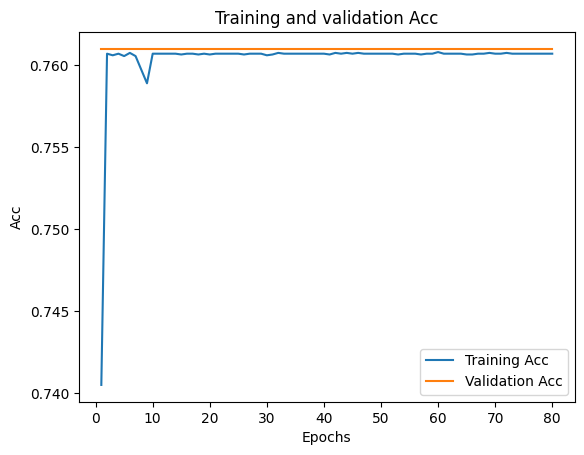

In [127]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, label='Training Acc')
plt.plot(epochs, val_acc, label='Validation Acc')
plt.title('Training and validation Acc')
plt.xlabel('Epochs')
plt.ylabel('Acc')
plt.legend()
plt.show()

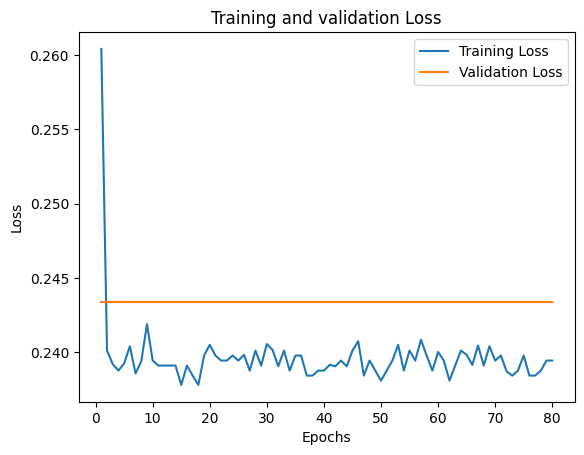

In [126]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)

plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training and validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [123]:
test_pred_nn = (model.predict(test_set) > 0.5).astype("int32")

344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 300us/step


In [124]:
#compute the performance of the model
report_scores(test_label, test_pred_nn)

              precision    recall  f1-score   support

        <=50       0.76      1.00      0.86      8360
         >50       0.00      0.00      0.00      2630

    accuracy                           0.76     10990
   macro avg       0.38      0.50      0.43     10990
weighted avg       0.58      0.76      0.66     10990



/Users/lorenzomannocci/anaconda3/envs/phd/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/lorenzomannocci/anaconda3/envs/phd/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/lorenzomannocci/anaconda3/envs/phd/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier

### Dropout and Random Forests: An Ensemble Analogy

**Random Forests** and **Dropout in Neural Networks** share a similar principle: creating **diverse models** and combining them to reduce overfitting.

---

### Random Forests

- **Ensemble of Decision Trees**: Each tree is trained on a **random subset of data** and a **random subset of features**.  
- **Diversity through Randomness**: Different trees see different “views” of the problem, leading to diverse patterns.  
- **Reducing Variance**: Predictions from all trees are **averaged**, stabilizing the output and reducing sensitivity to noise or outliers.

---

### Dropout in Neural Networks

- **Implicit Ensemble of Subnetworks**: At each training step, a **random subset of neurons is deactivated**, forming a different subnetwork.  
- **Diverse Subnetworks**: Each subnetwork learns slightly different patterns from the data.  
- **Implicit Ensemble Averaging**: At inference, the network uses **all neurons**, effectively averaging the outputs of many subnetworks, leading to **better generalization**.  

---

### Key Insight

Geoffrey Hinton’s paper on dropout compares it to **ensemble methods**, showing that dropout:

1. Mimics the effect of combining multiple models into one.  
2. Improves neural networks’ ability to **generalize** to new, unseen data.  

# Validation: dos and don'ts
Do:
- try different hyperparameter combinations sensibly, use the exhaustive search only if the hyperparameters change really has an effect and is time-manageable
- try different data preprocessings
- if enough data is available, use a separate dataset for model selection (see [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html#sklearn.model_selection.train_test_split) for a quick way to do it.)

Don't:
- select your model on the basis of the test set! The test set only *validates*: using it to select a model is cheating!